In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, soundfile as sf
from pathlib import Path
sns.set_theme(style="whitegrid")
Path("reports/eda").mkdir(parents=True, exist_ok=True)

AUDIO = Path(r"C:\Users\HP\Desktop\ing5\projet\projet_vishing\DATASET\audio")
meta = pd.read_csv(AUDIO / "audio_metadata.csv")
txt  = pd.read_excel("data/raw/DS07_aslc448/aslc448.xlsx")

files = {p.name: p for p in AUDIO.rglob("*.wav")}
meta["wav"] = meta["conversation_id"].map(lambda c: files.get(f"{c}.wav"))
print("WAV trouvés:", meta["wav"].notna().sum(), "/", len(meta))

df = txt.merge(meta[["conversation_id", "duration_sec", "wav"]], on="conversation_id", how="inner")
print(df.shape)
print("Conversations sans audio:", len(txt) - len(df))
print(txt[~txt.conversation_id.isin(df.conversation_id)].dialect.value_counts())

WAV trouvés: 422 / 422
(422, 20)
Conversations sans audio: 26
dialect
Yemeni    26
Name: count, dtype: int64


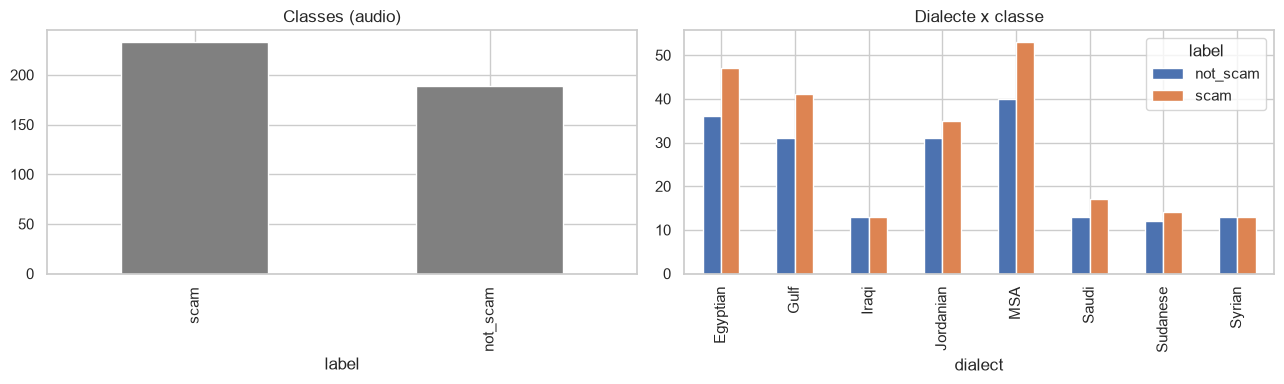

label      not_scam  scam
dialect                  
Egyptian         36    47
Gulf             31    41
Iraqi            13    13
Jordanian        31    35
MSA              40    53
Saudi            13    17
Sudanese         12    14
Syrian           13    13


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["label"].value_counts().plot.bar(ax=ax[0], color="gray", title="Classes (audio)")
pd.crosstab(df["dialect"], df["label"]).plot.bar(ax=ax[1], title="Dialecte x classe")
plt.tight_layout(); plt.savefig("reports/eda/01_classes_dialectes.png", dpi=150); plt.show()
print(pd.crosstab(df["dialect"], df["label"]))

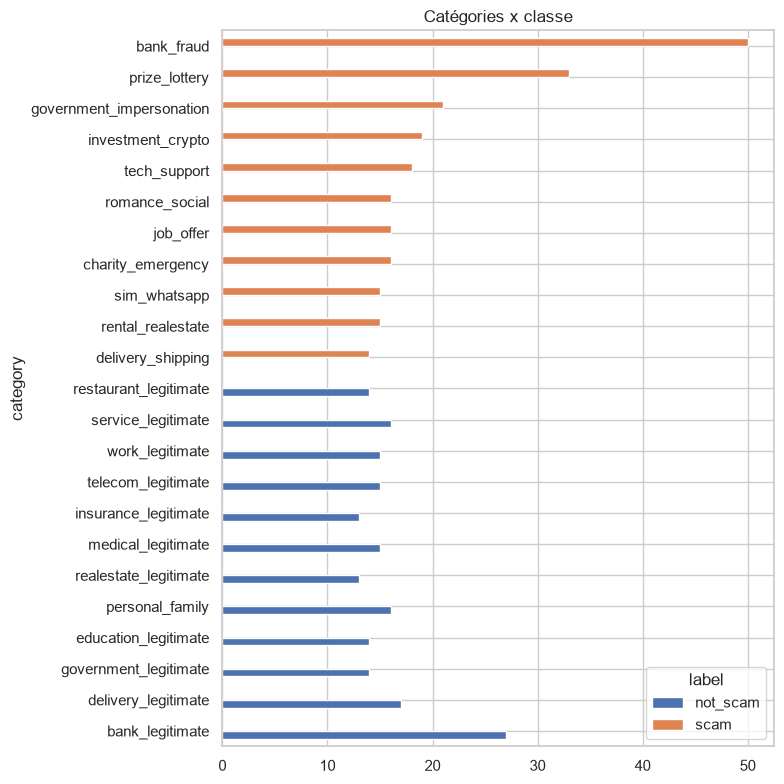

In [3]:
ct = pd.crosstab(df["category"], df["label"])
ct.sort_values("scam").plot.barh(figsize=(8, 8), title="Catégories x classe")
plt.tight_layout(); plt.savefig("reports/eda/02_categories.png", dpi=150); plt.show()

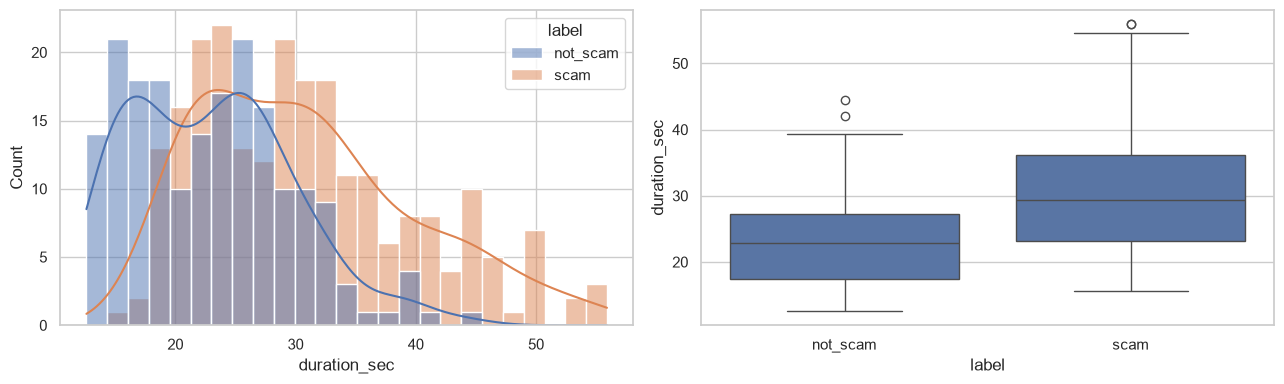

          count       mean       std   min   25%   50%   75%   max
label                                                             
not_scam  189.0  22.987831  6.718307  12.6  17.5  22.8  27.2  44.4
scam      233.0  30.823605  9.079766  15.6  23.1  29.4  36.1  55.9


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="duration_sec", hue="label", bins=25, kde=True, ax=ax[0])
sns.boxplot(data=df, x="label", y="duration_sec", ax=ax[1])
plt.tight_layout(); plt.savefig("reports/eda/03_duree.png", dpi=150); plt.show()
print(df.groupby("label")["duration_sec"].describe())

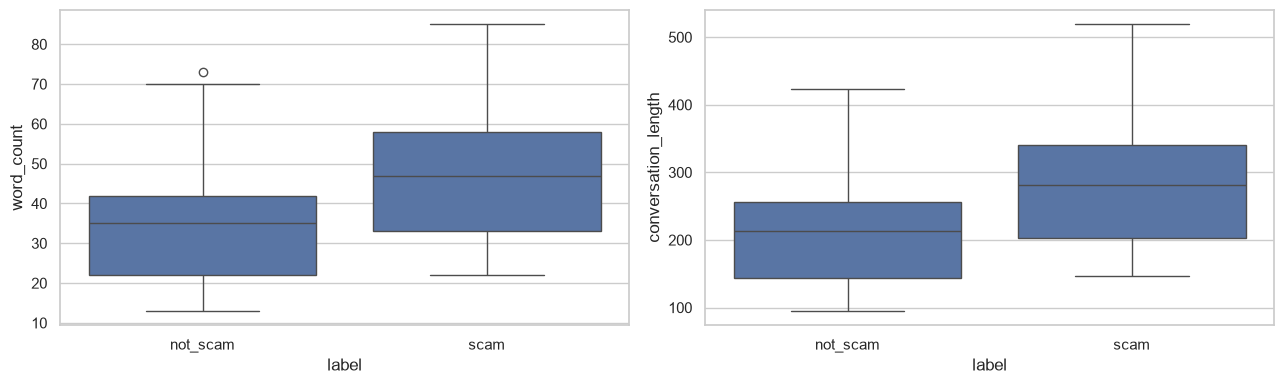

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="label", y="word_count", ax=ax[0])
sns.boxplot(data=df, x="label", y="conversation_length", ax=ax[1])
plt.tight_layout(); plt.savefig("reports/eda/04_texte.png", dpi=150); plt.show()

In [6]:
from sklearn.model_selection import train_test_split
y = (df["label"] == "scam").astype(int)
tr, te = train_test_split(df.index, test_size=0.2, stratify=y, random_state=42)
major = max(y[te].mean(), 1 - y[te].mean())
print(f"Classe majoritaire (test): {major:.3f}")

for col in ["duration_sec", "word_count", "conversation_length"]:
    best = (0, None, None)
    for t in np.unique(df.loc[tr, col]):
        for sign in (1, -1):
            pred = (sign * (df.loc[tr, col] - t) > 0).astype(int)
            acc = (pred == y[tr]).mean()
            if acc > best[0]: best = (acc, t, sign)
    acc_tr, t, sign = best
    acc_te = ((sign * (df.loc[te, col] - t) > 0).astype(int) == y[te]).mean()
    print(f"{col:22s} seuil={t:7.1f} sens={'>' if sign==1 else '<'}  train={acc_tr:.3f}  test={acc_te:.3f}")

Classe majoritaire (test): 0.553
duration_sec           seuil=   18.8 sens=>  train=0.688  test=0.729
word_count             seuil=   24.0 sens=>  train=0.691  test=0.682
conversation_length    seuil=  152.0 sens=>  train=0.694  test=0.647


In [7]:
info = [sf.info(p) for p in df["wav"].head(50)]
print("Sample rates:", {i.samplerate for i in info}, "| canaux:", {i.channels for i in info})
print("IDs dupliqués:", df["conversation_id"].duplicated().sum())
print("Textes dupliqués:", df["full_conversation"].duplicated().sum())

Sample rates: {24000} | canaux: {1}
IDs dupliqués: 0
Textes dupliqués: 0
